<a href="https://colab.research.google.com/github/PearSkyRich/ViT_CIFAR-100/blob/main/Run_ViTModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [3]:
class VisionTransformer(nn.Module):

    def __init__(
        self,
        image_size=32,
        patch_size=4,
        num_classes=100,
        embed_dim=192,
        depth=6,
        num_heads=6,
        mlp_dim=384,
        dropout=0.1
    ):
        super(VisionTransformer, self).__init__()

        self.patch_size = patch_size

        # Chuyển ảnh thành các patch
        self.patch_embedding = nn.Conv2d(
            in_channels=3,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        num_patches = (image_size // patch_size) ** 2

        # Class token
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        # Positional Embedding
        self.pos_embedding = nn.Parameter(
            torch.zeros(1, num_patches + 1, embed_dim)
        )

        self.dropout = nn.Dropout(dropout)

        # Transformer Encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=mlp_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=depth
        )

        self.norm = nn.LayerNorm(embed_dim)

        # Classification Head
        self.head = nn.Linear(embed_dim, num_classes)

        # Khởi tạo tham số
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embedding, std=0.02)

    def forward(self, x):

        # Bước 1: Patch Embedding
        x = self.patch_embedding(x)

        # [Batch, Embed_dim, 8, 8]
        x = x.flatten(2)

        # [Batch, 64, Embed_dim]
        x = x.transpose(1, 2)

        # Bước 2: Thêm Class Token
        cls_tokens = self.cls_token.expand(x.shape[0], -1, -1)

        x = torch.cat((cls_tokens, x), dim=1)

        # Bước 3: Thêm Positional Embedding
        x = x + self.pos_embedding

        x = self.dropout(x)

        # Bước 4: Transformer Encoder
        x = self.transformer(x)

        # Bước 5: Lấy đặc trưng từ Class Token
        x = self.norm(x[:, 0])

        # Bước 6: Phân loại
        x = self.head(x)

        return x

In [4]:
model = VisionTransformer().to(device)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/ViT_CIFAR100/best_vit_cifar100.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Đã tải mô hình ViT thành công!")

/tmp/ipykernel_793/1995245351.py:51: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Đã tải mô hình ViT thành công!


In [5]:
import torchvision

class_names = torchvision.datasets.CIFAR100(
    root="./data",
    train=False,
    download=True
).classes

print("Số lượng nhãn:", len(class_names))

100%|██████████| 169M/169M [44:49<00:00, 62.8kB/s]


Số lượng nhãn: 100


Saving GDLS-MPF.JPG.webp to GDLS-MPF.JPG.webp


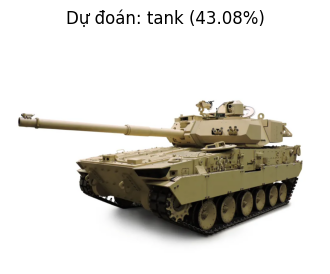

In [7]:
from google.colab import files
import io

# Khởi tạo transform cho ảnh phù hợp với đầu vào của ViT (32x32)
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5071, 0.4867, 0.4408], # Mean của CIFAR-100
        std=[0.2675, 0.2565, 0.2761]   # Std của CIFAR-100
    )
])

# Tải ảnh lên
uploaded = files.upload()

for fn in uploaded.keys():
    # Đọc ảnh
    image_bytes = uploaded[fn]
    image = Image.open(io.BytesIO(image_bytes)).convert("RGB")

    # Tiền xử lý ảnh và chuyển vào device
    input_tensor = transform(image).unsqueeze(0).to(device)

    # Dự đoán
    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)
        conf, preds = torch.max(probabilities, 1)

    predicted_class = class_names[preds.item()]
    confidence_score = conf.item() * 100

    # Hiển thị kết quả
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.title(f"Dự đoán: {predicted_class} ({confidence_score:.2f}%)")
    plt.axis("off")
    plt.show()


In [ ]:
# Định nghĩa trực tiếp 100 nhãn của CIFAR-100
class_names = [
    'apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle',
    'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel',
    'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock',
    'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur',
    'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster',
    'house', 'kangaroo', 'keyboard', 'lamp', 'lawn_mower', 'leopard', 'lion',
    'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain',
    'mouse', 'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree',
    'pear', 'pickup_truck', 'pine_tree', 'plain', 'plate', 'poppy', 'porcupine',
    'possum', 'rabbit', 'raccoon', 'ray', 'road', 'rocket', 'rose',
    'sea', 'seal', 'shark', 'shrew', 'skunk', 'skyscraper', 'snail', 'snake',
    'spider', 'squirrel', 'streetcar', 'sunflower', 'sweet_pepper', 'table',
    'tank', 'telephone', 'television', 'tiger', 'tractor', 'train', 'trout',
    'tulip', 'turtle', 'wardrobe', 'whale', 'willow_tree', 'wolf', 'woman', 'worm'
]

print("Đã tải thành công", len(class_names), "nhãn cứng mà không cần download dataset!")

In [8]:
import json
import os

# Đường dẫn thư mục lưu trữ trên Google Drive
drive_path = "/content/drive/MyDrive/ViT_CIFAR100"
os.makedirs(drive_path, exist_ok=True)

# Đường dẫn file JSON
json_path = os.path.join(drive_path, "cifar100_classes.json")

# Lưu danh sách nhãn vào file JSON
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=4)

print(f"Đã lưu thành công danh sách nhãn vào: {json_path}")

Đã lưu thành công danh sách nhãn vào: /content/drive/MyDrive/ViT_CIFAR100/cifar100_classes.json


 Sau này khi muốn khởi tạo lại mô hình mà không cần tải bộ dữ liệu CIFAR-100, bạn chỉ cần chạy đoạn mã dưới đây để lấy danh sách nhãn:

```python
import json

with open("/content/drive/MyDrive/ViT_CIFAR100/cifar100_classes.json", "r", encoding="utf-8") as f:
    class_names = json.load(f)

print("Số lượng nhãn tải từ Drive:", len(class_names))
```

In [ ]:
from google.colab import files
import io
import json
import os
import torch
import matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms as transforms

# 1. Đảm bảo nhãn class_names đã được load từ Drive
json_path = "/content/drive/MyDrive/ViT_CIFAR100/cifar100_classes.json"
if 'class_names' not in locals() or class_names is None:
    if os.path.exists(json_path):
        with open(json_path, "r", encoding="utf-8") as f:
            class_names = json.load(f)
        print("Đã tải thành công danh sách nhãn từ Drive.")
    else:
        raise FileNotFoundError("Không tìm thấy file JSON lưu nhãn trên Drive. Hãy chắc chắn bạn đã chạy cell lưu JSON trước đó!")

# 2. Định nghĩa hàm tiền xử lý ảnh (transforms)
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5071, 0.4867, 0.4408],
        std=[0.2675, 0.2565, 0.2761]
    )
])

# 3. Yêu cầu tải ảnh lên
print("Vui lòng chọn một hoặc nhiều ảnh để dự đoán:")
uploaded = files.upload()

if not uploaded:
    print("Bạn chưa chọn ảnh nào!")
else:
    for fn in uploaded.keys():
        print(f"\n--- Đang xử lý ảnh: {fn} ---")
        # Đọc và chuyển đổi định dạng ảnh
        image_bytes = uploaded[fn]
        image = Image.open(io.BytesIO(image_bytes)).convert("RGB")

        # Chuẩn bị tensor đưa vào mô hình
        input_tensor = transform(image).unsqueeze(0).to(device)

        # Tiến hành dự đoán không tính gradient
        with torch.no_grad():
            outputs = model(input_tensor)
            probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]

        # Lấy top 5 dự đoán tốt nhất
        top5_prob, top5_catid = torch.topk(probabilities, 5)

        # Biến đổi định dạng để vẽ đồ thị
        probs = [p.item() * 100 for p in top5_prob]
        labels = [class_names[cid.item()] for cid in top5_catid]

        # Hiển thị trực quan: bên trái là ảnh, bên phải là biểu đồ cột top 5
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

        # Vẽ ảnh gốc
        ax1.imshow(image)
        ax1.set_title(f"Ảnh đầu vào: {fn}")
        ax1.axis("off")

        # Vẽ biểu đồ cột xác suất
        y_pos = range(len(labels))
        bars = ax2.barh(y_pos, probs, align='center', color='skyblue')
        ax2.set_yticks(y_pos)
        ax2.set_yticklabels(labels)
        ax2.invert_yaxis()  # Đảo ngược trục Y để nhãn cao nhất nằm trên cùng
        ax2.set_xlabel('Độ tin cậy (%)')
        ax2.set_title('Top 5 Dự đoán cao nhất')
        ax2.set_xlim(0, 100)

        # Thêm nhãn text ghi phần trăm cụ thể bên cạnh mỗi cột
        for bar in bars:
            width = bar.get_width()
            ax2.text(width + 1, bar.get_y() + bar.get_height()/2, f'{width:.1f}%',
                     ha='left', va='center', fontsize=9)

        plt.tight_layout()
        plt.show()